# Predicción de Churn Telefonía móvil

Las comunicaciones por teléfono móvil siempre han sido objeto de una feroz competencia, en la que, usualmente, hay un número reducido de competidores (operadores) en el mercado que oscila entre cuatro y seis. Los operadores deben hacer fuertes inversiones de entrada para poder operar y prestar un servicio adecuado. El mercado de telefonía móvil está usualmente saturado (poca posibilidad de ampliación del mercado) y, por tanto, el conjunto de consumidores disponibles es reducido, por lo que los operadores usualmente cambian su estrategia de adquisición de clientes a una de retención, pues en el mundo se calcula que el costo de adquirir un nuevo cliente es cinco veces superior al de retenerlo- El esfuerzo fundamental se centra en predecir la deserción (churn) para poderla prevenir.

Un operador de telecomunicaciones les ha contratado para tener una mejor predicción de churn. Les otorga una base de datos de entrenamiento (que es una muestra aleatoria simple de la base de datos total de la compañía) que contiene el resultado de retención en los últimos seis meses y les pide que se realice la mejor predicción posible (basada en el área bajo la curva COR) para una base de datos de prueba en un concurso de Kaggle. Pide también un reporte con metodología CRISP-DM (de máximo 6 páginas) de los modelos realizados.

## Importación de librerias y datos

In [32]:
%pip install pandas openpyxl scikit-learn imblearn xgboost

   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
   ---------------------------------------- 1.3/124.9 MB 8.4 MB/s eta 0:00:15
   - -------------------------------------- 3.1/124.9 MB 8.8 MB/s eta 0:00:14
   - -------------------------------------- 4.7/124.9 MB 8.4 MB/s eta 0:00:15
   -- ------------------------------------- 6.6/124.9 MB 8.4 MB/s eta 0:00:15
   -- ------------------------------------- 8.4/124.9 MB 8.5 MB/s eta 0:00:14
   --- ------------------------------------ 10.0/124.9 MB 8.4 MB/s eta 0:00:14
   --- ------------------------------------ 11.8/124.9 MB 8.5 MB/s eta 0:00:14
   ---- ----------------------------------- 13.1/124.9 MB 8.4 MB/s eta 0:00:14
   ---- ----------------------------------- 14.9/124.9 MB 8.3 MB/s eta 0:00:14
   ----- ---------------------------------- 17.3/124.9 MB 8.6 MB/s eta 0:00:13
   ------ --------------------------------- 19.1/124.9 MB 8.6 MB/s eta 0:00:13
   ------ --------------------------------- 21.0/124.9 MB 8.7 MB/

In [2]:
import pandas as pd
import numpy as np

In [3]:
data_train = pd.read_excel('./files/traintelco.xlsx')
data_test = pd.read_excel('./files/testelco.xlsx')

In [4]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8243 entries, 0 to 8242
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     8243 non-null   int64         
 1   Fecha de nacimiento    8243 non-null   datetime64[ns]
 2   tipo cliente           8243 non-null   int64         
 3   Factura online         8243 non-null   int64         
 4   Antigüedad Equipo      8243 non-null   int64         
 5   Plan de datos          8243 non-null   int64         
 6   facturación            8243 non-null   int64         
 7   mora                   8243 non-null   int64         
 8   Fecha inicio contrato  8243 non-null   datetime64[ns]
 9   minutos                8243 non-null   int64         
 10  resultado              8243 non-null   int64         
dtypes: datetime64[ns](2), int64(9)
memory usage: 708.5 KB


In [5]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     2000 non-null   int64         
 1   Fecha de nacimiento    2000 non-null   datetime64[ns]
 2   tipo cliente           2000 non-null   int64         
 3   Factura online         2000 non-null   int64         
 4   Antigüedad Equipo      2000 non-null   int64         
 5   Plan de datos          2000 non-null   int64         
 6   facturación            2000 non-null   int64         
 7   mora                   2000 non-null   int64         
 8   Fecha inicio contrato  2000 non-null   datetime64[ns]
 9   minutos                2000 non-null   int64         
dtypes: datetime64[ns](2), int64(8)
memory usage: 156.4 KB


## Limpieza de datos

In [6]:
data_train_clean = data_train.copy()
data_test_clean = data_test.copy()

Calculo de la edad de la persona para reemplazarlo por la fecha de nacimiento, se considera como un dato predictivo de mayor peso

In [7]:
# Calculate age from birth year and drop birth year
def calculate_age(df):
    df['age'] = 2018 - df['Fecha de nacimiento'].dt.year
    df = df.drop(columns=['Fecha de nacimiento'])
    return df

data_train_clean = calculate_age(data_train_clean)
data_test_clean = calculate_age(data_test_clean)

Dummificación de el tipo de cliente

In [8]:
# Dummy variables for 'tipo cliente' and drop 'tipo cliente'
def dummy(df, columns):
    df = pd.get_dummies(df, columns=columns)
    df = df.rename(columns={'tipo cliente_1': 'hombre', 'tipo cliente_2': 'mujer', 'tipo cliente_3': 'empresarial'})
    return df

columns = ['tipo cliente']
data_train_clean = dummy(data_train_clean, columns)
data_test_clean = dummy(data_test_clean, columns)

Se cambia el valor de fecha de contrato por una variable cuantitativa que representa qué tan nuevo es el contrato

In [9]:
# Extract timestamp from date
def extract_timestamp(df):
    column = 'Fecha inicio contrato'
    df[column] = pd.to_datetime(df[column])
    df[column] = df[column].astype(np.int64) // 10**9
    df = df.rename(columns={'Fecha inicio contrato': 'novedad del contrato'})
    return df

data_train_clean = extract_timestamp(data_train_clean)
data_test_clean = extract_timestamp(data_test_clean)

Estandarización de variables cuantitativas

In [10]:
# Standardize numerical variables
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
columns = ['novedad del contrato', 'facturación', 'mora', 'minutos', 'Antigüedad Equipo', 'age']

data_train_clean[columns] = scaler.fit_transform(data_train_clean[columns])
data_test_clean[columns] = scaler.transform(data_test_clean[columns])

In [11]:
# Drop id column
data_train_clean = data_train_clean.drop(columns=['id'])
# save ids in a separate dataframe for later
ids = data_test_clean['id']
data_test_clean = data_test_clean.drop(columns=['id'])

In [12]:
data_train_clean

,Factura online,Antigüedad Equipo,Plan de datos,facturación,mora,novedad del contrato,minutos,resultado,age,hombre,mujer,empresarial
0,1,-1.007978,0,-2.334734,0.754564,1.023311,-0.578726,0,-6.585613,False,True,False
1,0,1.104213,1,0.771149,-0.719395,0.598030,-0.558356,0,-4.542519,False,True,False
2,0,0.906195,1,-0.388154,0.088905,0.514947,-0.155260,1,-5.359756,False,True,False
3,1,-0.875966,1,-0.653097,-0.434113,0.204387,-0.695581,0,-5.768375,False,True,False
4,1,-1.205996,0,1.692216,-0.862036,-1.495751,0.734555,0,-5.768375,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8238,1,-1.139990,1,-0.746119,0.421734,-0.083921,8.265818,1,-0.660641,False,True,False
8239,1,-0.743954,0,-0.106995,-0.719395,0.282078,-0.559428,0,-0.864950,True,False,False
8240,1,-0.941972,1,0.212065,1.087393,1.054913,0.301441,0,-0.660641,False,True,False
8241,0,0.576165,1,-0.629130,-0.719395,0.631053,-0.739535,0,2.199690,True,False,False


## Entrenamiento del modelo

División de variables predictoras y dependiente y Cross Validation

In [13]:
X = data_train_clean.drop(columns=['resultado'])
Y = data_train_clean['resultado']

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

Verificar balanceo de datos

In [15]:
# Count number of 0s and 1s percentage in the training set
Y_train.value_counts(normalize=True)

resultado
0    0.835456
1    0.164544
Name: proportion, dtype: float64

### Modelos

#### Regresion logistica

In [36]:
# LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, Y_train)

LogisticRegression()

#### Arbol de decision CHAID

In [65]:
# MODEL: CHAID DECISION TREE
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(criterion='gini', random_state=42)
model.fit(X_train, Y_train)

DecisionTreeClassifier(random_state=42)

#### KNN

In [67]:
# MODEL: KNN
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, Y_train)

KNeighborsClassifier()

#### SVM

In [39]:
# MODEL: SVM
from sklearn.svm import SVC

model = SVC(kernel='rbf', random_state=42)
model.fit(X_train, Y_train)

SVC(random_state=42)

#### Random Forest Embebido

In [16]:
# MODEL: EMBEDDED RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(min_samples_split=10, max_depth=10, min_samples_leaf=8, n_estimators=400, random_state=42, class_weight=None)
model.fit(X_train, Y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=8, min_samples_split=10,
                       n_estimators=400, random_state=42)

#### Random Forest con primer intento en parametros (Posible Overfitting)

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Configuración inicial del modelo
initial_model = RandomForestClassifier(random_state=42)

# Definir el espacio de búsqueda inicial para RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# Primer paso de búsqueda: una búsqueda aleatoria con RandomizedSearchCV
random_search = RandomizedSearchCV(
    initial_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1
)

# Entrenar el primer paso de búsqueda aleatoria
random_search.fit(X_train, Y_train)

# Mejor estimador encontrado en el primer paso
best_model = random_search.best_estimator_

# Ajuste adicional "stepwise" al refinar el espacio de búsqueda en torno a los mejores parámetros
# Extraemos los mejores parámetros y creamos un nuevo rango de búsqueda más centrado
best_params = random_search.best_params_

# Actualizar el espacio de búsqueda centrado en torno a los mejores parámetros
param_dist_refined = {
    'n_estimators': [best_params['n_estimators'] - 50, best_params['n_estimators'], best_params['n_estimators'] + 50],
    'max_depth': [best_params['max_depth'] - 5 if best_params['max_depth'] else None, best_params['max_depth'], 
                  best_params['max_depth'] + 5 if best_params['max_depth'] else None],
    'min_samples_split': [best_params['min_samples_split'] - 1, best_params['min_samples_split'], best_params['min_samples_split'] + 1]
}

# Configurar la búsqueda refinada con RandomizedSearchCV
refined_search = RandomizedSearchCV(
    best_model,
    param_distributions=param_dist_refined,
    n_iter=10,  # Menor número de combinaciones, ajustando alrededor de los mejores parámetros
    scoring='recall',  # Cambiar el criterio de optimización a recall para mejorar el balance de clases
    cv=3,
    random_state=42,
    n_jobs=-1
)

# Entrenar la búsqueda refinada de hiperparámetros
refined_search.fit(X_train, Y_train)

# Mejor modelo encontrado después del ajuste "stepwise"
model = refined_search.best_estimator_

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
9 fits failed out of a total of 30.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
9 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1466, in wrapper
    estimator._validate_params()
  File "c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", lin

### Random Forest con hiperparametros ajustados para evitar Overfitting

In [21]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Definir el modelo base con class_weight='balanced' para manejar desequilibrio
model = RandomForestClassifier(random_state=42, class_weight='balanced')

# Ajuste progresivo de parámetros para reducir el sobreajuste
param_dist = {
    'n_estimators': [100, 150, 200],  # Reducimos el número de estimadores
    'max_depth': [10, 15, 20],  # Aumentamos ligeramente la profundidad
    'min_samples_split': [10, 15, 20],  # Aumentamos para reducir sobreajuste
    'min_samples_leaf': [5, 10, 15],  # Aumentamos el mínimo de muestras en hojas
    'max_features': ['sqrt', 'log2']  # Usamos solo valores válidos para max_features
}

# Configurar RandomizedSearchCV con validación cruzada aumentada
random_search = RandomizedSearchCV(
    model,
    param_distributions=param_dist,
    n_iter=20,  # Número de combinaciones a probar
    scoring='roc_auc',  # Optimizar para AUC
    cv=5,  # Validación cruzada con 5 folds para mejor generalización
    random_state=42,
    n_jobs=-1
)

# Entrenar la búsqueda aleatoria de hiperparámetros
random_search.fit(X_train, Y_train)

# Mejor modelo después de la búsqueda
model = random_search.best_estimator_

# Imprimir los mejores parámetros encontrados
print("Best parameters:", random_search.best_params_)
print("Best score:", random_search.best_score_)
print("Best estimator:", random_search.best_estimator_)


Best parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'log2', 'max_depth': 10}
Best score: 0.8505177701188471
Best estimator: RandomForestClassifier(class_weight='balanced', max_depth=10,
                       max_features='log2', min_samples_leaf=5,
                       min_samples_split=10, n_estimators=200, random_state=42)


In [22]:
len(data_test)

2000

## Modelo a Usar (0.783)

### Busqueda de mejores hiperparametros

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dividir datos en entrenamiento y prueba, estratificando para mantener proporción de clases
X_train_bal, X_test_bal, Y_train_bal, Y_test_bal = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

# Definir el modelo base
gb_model = GradientBoostingClassifier(random_state=42)

# Espacio de hiperparámetros para RandomizedSearchCV
param_dist = {
    'n_estimators': [500, 800, 1000, 1200],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'min_samples_split': [20, 50, 100],
    'min_samples_leaf': [10, 20, 30],
    'subsample': [0.6, 0.7, 0.8],
    'max_features': ['sqrt', 'log2', None],
    'loss': ['log_loss']
}

# Configurar RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=param_dist,
    n_iter=50,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# Buscar los mejores hiperparámetros
random_search.fit(X_train_bal, Y_train_bal)
best_gb_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)

# Predecir probabilidades en el conjunto de prueba
Y_pred_proba = best_gb_model.predict_proba(X_test_bal)[:, 1]

# Encontrar el umbral óptimo usando la curva ROC
fpr, tpr, thresholds = roc_curve(Y_test_bal, Y_pred_proba)
optimal_idx = np.argmax(tpr - fpr)  # Maximizar TPR - FPR para priorizar recall
optimal_threshold = thresholds[optimal_idx]
print(f"Optimal Threshold (prioritizing recall): {optimal_threshold}")

# Usar el umbral óptimo para generar predicciones
Y_pred = (Y_pred_proba >= optimal_threshold).astype(int)

# Calcular métricas en el conjunto de prueba
metrics = {
    "Accuracy": accuracy_score(Y_test_bal, Y_pred),
    "Precision": precision_score(Y_test_bal, Y_pred),
    "Recall": recall_score(Y_test_bal, Y_pred),
    "F1": f1_score(Y_test_bal, Y_pred),
    "AUC": roc_auc_score(Y_test_bal, Y_pred_proba)
}

print("Metrics:", metrics)

# Graficar la curva ROC
plt.figure()
plt.plot(fpr, tpr, label=f'GradientBoosting (AUC = {metrics["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--')  # Línea diagonal
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

# Entrenar el modelo en todo el conjunto de entrenamiento con los mejores hiperparámetros
final_model = best_gb_model.fit(X_train, Y_train)

# Generar predicciones finales en el conjunto de prueba
test_proba = final_model.predict_proba(data_test_clean)[:, 1]
test_pred = (test_proba >= optimal_threshold).astype(int)

# Guardar las predicciones en un archivo CSV
submission = pd.DataFrame({'id': ids, 'resultado': test_pred})
submission.to_csv('submission.csv', index=False)


### Prueba y error con modificación de hiperparametros que estaban cercanos a los bordes.

Optimal Threshold (prioritizing recall): 0.1734020886460179
Metrics: {'Accuracy': 0.8180715585203153, 'Precision': 0.4699570815450644, 'Recall': 0.8051470588235294, 'F1': 0.5934959349593496, 'AUC': 0.8976996027169037}


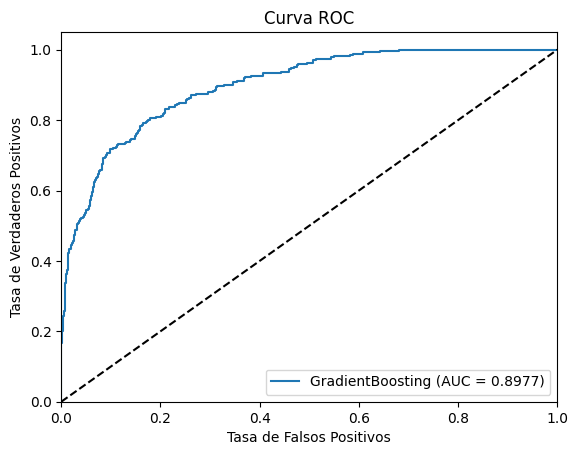

In [46]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dividir datos en entrenamiento y prueba, estratificando para mantener proporción de clases
X_train_bal, X_test_bal, Y_train_bal, Y_test_bal = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

# Definir el modelo con parámetros ajustados
best_gb_model = GradientBoostingClassifier(
    n_estimators=1200,
    max_depth=4,
    learning_rate=0.01,
    min_samples_split=50,
    min_samples_leaf=20,
    subsample=0.7,
    max_features='sqrt',
    loss='log_loss',
    random_state=42
)

# Entrenar el modelo con los datos estratificados
best_gb_model.fit(X_train_bal, Y_train_bal)

# Predecir probabilidades en el conjunto de prueba
Y_pred_proba = best_gb_model.predict_proba(X_test_bal)[:, 1]

# Encontrar el umbral óptimo usando la curva ROC
fpr, tpr, thresholds = roc_curve(Y_test_bal, Y_pred_proba)
optimal_idx = np.argmax(tpr - fpr)  # Maximizar TPR - FPR para priorizar recall
optimal_threshold = thresholds[optimal_idx]
print(f"Optimal Threshold (prioritizing recall): {optimal_threshold}")

# Usar el umbral óptimo para generar predicciones
Y_pred = (Y_pred_proba >= optimal_threshold).astype(int)

# Calcular métricas en el conjunto de prueba
metrics = {
    "Accuracy": accuracy_score(Y_test_bal, Y_pred),
    "Precision": precision_score(Y_test_bal, Y_pred),
    "Recall": recall_score(Y_test_bal, Y_pred),
    "F1": f1_score(Y_test_bal, Y_pred),
    "AUC": roc_auc_score(Y_test_bal, Y_pred_proba)
}

print("Metrics:", metrics)

# Graficar la curva ROC
plt.figure()
plt.plot(fpr, tpr, label=f'GradientBoosting (AUC = {metrics["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--')  # Línea diagonal
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

# Entrenar el modelo en todo el conjunto de entrenamiento
final_model = best_gb_model.fit(X_train, Y_train)

# Generar predicciones finales en el conjunto de prueba
test_proba = final_model.predict_proba(data_test_clean)[:, 1]
test_pred = (test_proba >= optimal_threshold).astype(int)

# Guardar las predicciones en un archivo CSV
submission = pd.DataFrame({'id': ids, 'resultado': test_pred})
submission.to_csv('submission.csv', index=False)


## Evaluación del modelo

In [42]:
# evaluate model
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_auc_score

accuracy = accuracy_score(Y_test, y_pred)
f1 = f1_score(Y_test, y_pred)
recall_score = recall_score(Y_test, y_pred)
precision_score = precision_score(Y_test, y_pred)
auc = roc_auc_score(Y_test, y_pred)

print(f'Accuracy: {accuracy}')
print(f'F1 score: {f1}')
print(f'Recall: {recall_score}')
print(f'Precision: {precision_score}')
print(f'AUC: {auc}')

NameError: name 'model' is not defined

## Creacion de sometimiento

In [20]:
# use the model to predict the test data
y_test_pred = model.predict(data_test_clean)

# save the predictions to a csv file
submission = pd.DataFrame({'id': ids, 'resultado': y_test_pred})
submission.to_csv('submission.csv', index=False)

Grupo:
- Esteban Salazar Arbeláez
- Juan Francisco Ramírez Escobar
- Javier Alejandro Moyano Cipamocha